In [14]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt


DATA_DIR = Path("../Data")

print("chemin : ",DATA_DIR.resolve())#le chemin complet
print("le doccier existe :",DATA_DIR.exists())#virifier si le doccier exist

# les nom des doccier

# if DATA_DIR.exists():
#     print("Contenu du doccier data :")
#     for ele in DATA_DIR.iterdir():
#         print(ele.name)


class_names=[]
for ele in DATA_DIR.iterdir():
    class_names.append(ele.name)
# print(class_name)


extensions_valides={".jpg",".jpeg",".png",".bmp"}

image_counts={}

for class_name in class_names:
    class_dir=DATA_DIR / class_name

    images = [
        file
        for file in class_dir.rglob("*")
        if file.is_file()
        and file.suffix.lower() in extensions_valides
    ]

    image_counts[class_name]=len(images)


print("le nombre dimage par class :")
# print(image_counts)
for class_name ,count in image_counts.items():
    print(f"{class_name} : {count} images")

chemin :  C:\BrainScan\Data
le doccier existe : True
le nombre dimage par class :
glioma : 1621 images
meningioma : 1645 images
notumor : 2000 images
pituitary : 1757 images


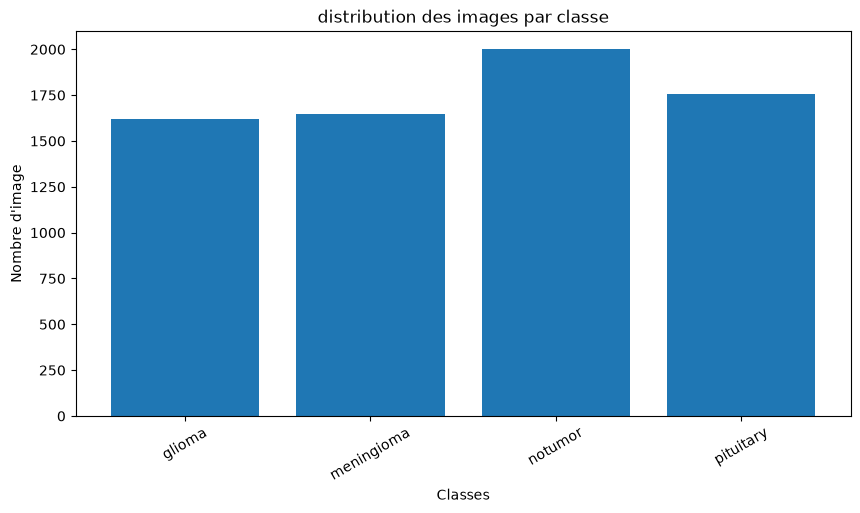

In [25]:
plt.figure(figsize=(10,5))

plt.bar(
    image_counts.keys(),
    image_counts.values()
)

plt.title("distribution des images par classe")
plt.xlabel("Classes")
plt.ylabel("Nombre d'image")
plt.xticks(rotation=30)
plt.show()

# print(image_counts)

In [ ]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

# recuperer le chemains des imgs
image_path=[]
labels=[]

for class_name in class_names:
    class_dir=DATA_DIR/ class_name

    for file in class_dir.rglob("*"):
        if file.is_file() and file.suffix.lower() in extensions_valides:
            image_path.append(file)
            labels.append(class_name)


print("Nombre de chemins :",len(image_path))
print("Nombre de labels :",len(labels))

# print(image_path)
# print(labels)


Nombre de chemins : 7023
Nombre de labels : 7023


In [ ]:
# virifier que image est lisible

if image_path:
    try:
        image=Image.open(image_path[0])
        image.verify()#virifier si li file valide ou non 

        print("image valide :",image_path[0])
        print("Format : ",image.format)
        print("Dimension :",image.size)
    except Exception as error:
        print("erreur :",error)
else:
    print("aucun img trouve")

image valide : ..\Data\glioma\Te-glTr_0000.jpg
Format :  JPEG
Dimension : (512, 512)


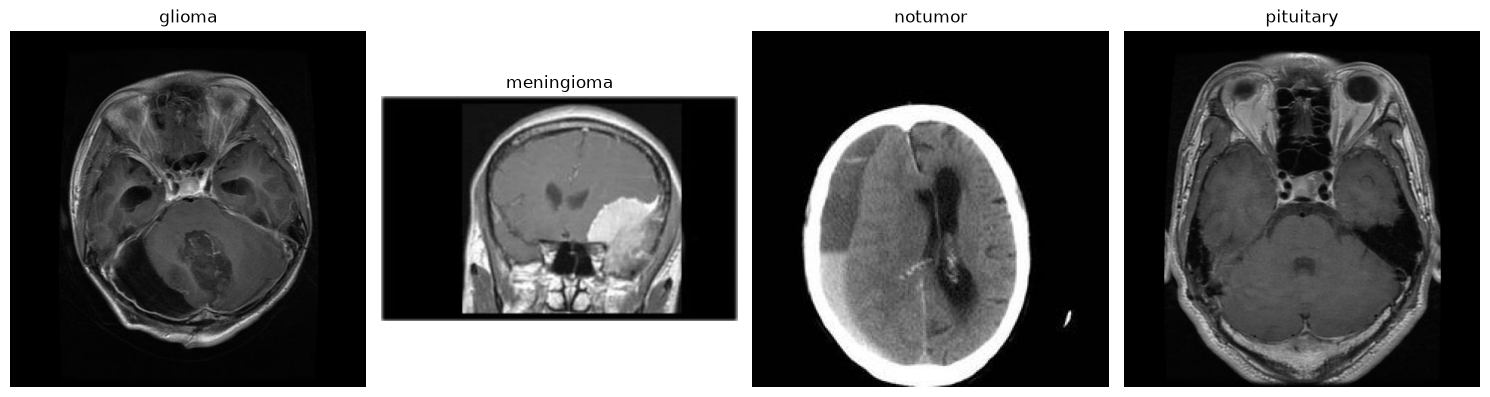

In [ ]:
# afficher quelque img avce leur labels

fig,axes=plt.subplots(1,len(class_names),figsize=(15,4))#crer 4 espace

for ax,class_name in zip(axes,class_names):#associer chque  image a son label
    class_images=[
        path for path,label in zip(image_path,labels)
        if label == class_name
    ]

    if class_images:
        try:
            with Image.open(class_images[0]) as image:
                ax.imshow(image.convert("RGB"))#convertit limg en trois canaux de couleur pour faciliter leur affichage

            ax.set_title(class_name)
            ax.axis("off")#masque les axes inutiles
        except Exception as error:
            ax.set_title(f"erreur : {class_name}")
            ax.axis("off")
            print(class_name,error)

plt.tight_layout()
plt.show()

In [ ]:
# nettoyer et preparer les imgs

valide_paths=[]
valide_labels=[]
invalid_img=[]

for path,label in zip(image_path,labels):
    try:
        with Image.open(path) as img:
            img.verify()

        valide_paths.append(path)
        valide_labels.append(labels)
    except Exception as error:
        invalid_img.append((path,str(error)))

print("images trouve :",len(image_path))
print("image valides :",len(valide_paths))
print("image invalides :",len(invalid_img))

images trouve : 7023
image valides : 7023
image invalides : 0


In [ ]:
# melange les images

import random

random.seed(42)

data=list(zip(valide_paths,valide_labels))#creation de paire (path,label)
random.shuffle(data)

image_path,labels = zip(*data)

image_path = list(image_path)
labels = list(labels)

print("nombre d'images :",len(image_path))
print("nombre labels :",len(labels))

print("la premiere class apres melange :",labels[:10])

la premiere class apres melange : [['glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'gli

In [ ]:
# redimensionnement des imgs

IMG_SIZE=(224,224)

images_resized=[]
labels_resized=[]

for path,label in zip(image_path,labels):
    try:
        with Image.open(path) as img:
            img=img.convert("RGB")#3 canaux
            img=img.resize(IMG_SIZE)

            images_resized.append(np.array(img))#convertit limg en tableau numerique
            labels_resized.append(label)
    except Exception as error:
        print("erreur avec {path} : {error}")

x=np.array(images_resized,dtype=np.uint8)
y=np.array(labels_resized)

print("dimensions de x :", x.shape)
print("dimensions de y :", y.shape)

dimensions de x : (7023, 224, 224, 3)
dimensions de y : (7023, 7023)


In [ ]:
# normalise les pix

X=x.astype("float32")/255.0
print("Valeur minimale :", X.min())
print("Valeur maximale :", X.max())
print("Type des données :", X.dtype)

Valeur minimale : 0.0
Valeur maximale : 1.0
Type des données : float32


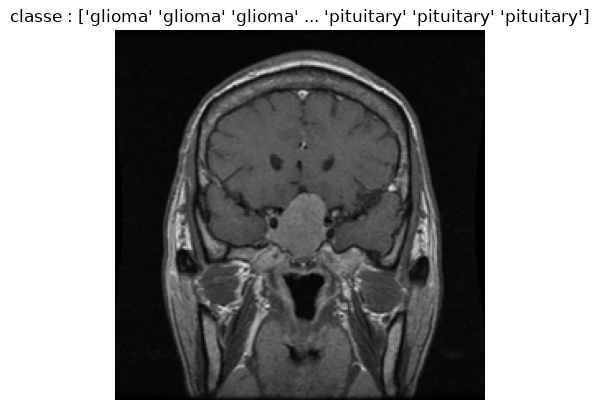

In [50]:

plt.imshow(x[0])
plt.title(f"classe : {y[0]}")
plt.axis("off")
plt.show()